# Assignment 4: Advanced Applications in Math and Python

**Name:** G Anirudh
**Register No.:** RA2411003012249

| Part | Task | Topics |
|---|---|---|
| 1.1 | Covariance and correlation matrices | Linear algebra, statistics |
| 1.2 | Markov chain weather model | Probability, eigenvectors |
| 2.1 | Time-series windowing | Pandas rolling and expanding windows, NaN handling |
| 2.2 | Subplots with conditional colour and shading | Matplotlib, empirical rule |

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

np.random.seed(7)
pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 110
RESULTS = {}   # collected for the dashboard

## Part 1.1: Covariance and Correlation Matrices

Three simulated sensor channels (temperature in °C, relative humidity in %, pressure in hPa),
100 readings each, drawn from a multivariate normal distribution. A 3×100 matrix `X` holds
one variable per row.

The sample covariance matrix comes straight from matrix multiplication:

$$C = \frac{1}{n-1}\,(X - \bar{X})(X - \bar{X})^{T}$$

where $\bar{X}$ is each row's mean, broadcast across its 100 columns. The result is 3×3.

In [2]:
names = ["Temperature", "Humidity", "Pressure"]
true_mean = np.array([30.0, 65.0, 1008.0])
true_cov = np.array([[ 4.0, -6.0, -1.5],
                     [-6.0, 25.0,  2.0],
                     [-1.5,  2.0,  3.0]])

X = np.random.multivariate_normal(true_mean, true_cov, size=100).T   # shape (3, 100)
print("X shape:", X.shape)
print("First 5 readings of each sensor:")
print(np.round(X[:, :5], 2))

X shape: (3, 100)
First 5 readings of each sensor:
[[  28.28   30.34   32.95   29.73   29.38]
 [  73.63   67.38   65.96   68.24   67.59]
 [1008.2  1007.07 1006.29 1007.26 1007.68]]


In [3]:
n = X.shape[1]
row_means = X.mean(axis=1, keepdims=True)    # (3, 1)
Xc = X - row_means                            # centre each variable
C_manual = (Xc @ Xc.T) / (n - 1)              # (3,100) @ (100,3) -> (3,3)

print("Covariance matrix (manual, matrix multiplication):")
print(np.round(C_manual, 4))

Covariance matrix (manual, matrix multiplication):
[[ 3.1135 -4.6602 -0.5254]
 [-4.6602 23.1032 -0.2251]
 [-0.5254 -0.2251  2.39  ]]


Verification with the built-in function:

In [4]:
C_numpy = np.cov(X)          # rows are variables by default
diff = np.abs(C_manual - C_numpy).max()
print("np.cov(X):")
print(np.round(C_numpy, 4))
print(f"\nLargest absolute difference: {diff:.2e}")
print("Match:", np.allclose(C_manual, C_numpy))

np.cov(X):
[[ 3.1135 -4.6602 -0.5254]
 [-4.6602 23.1032 -0.2251]
 [-0.5254 -0.2251  2.39  ]]

Largest absolute difference: 3.55e-15
Match: True


The correlation matrix rescales covariance by each variable's standard deviation:
$R = D^{-1} C D^{-1}$, where $D$ is the diagonal matrix of standard deviations.

In [5]:
D_inv = np.diag(1 / np.sqrt(np.diag(C_manual)))
R_manual = D_inv @ C_manual @ D_inv
R_numpy = np.corrcoef(X)
print("Correlation matrix (manual):")
print(np.round(R_manual, 4))
print("Match with np.corrcoef:", np.allclose(R_manual, R_numpy))

Correlation matrix (manual):
[[ 1.     -0.5495 -0.1926]
 [-0.5495  1.     -0.0303]
 [-0.1926 -0.0303  1.    ]]
Match with np.corrcoef: True


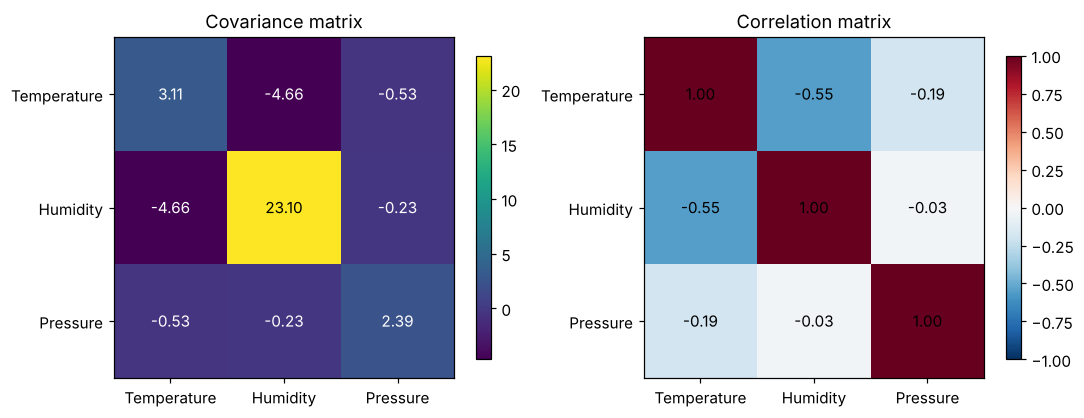

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, M, title, cmap in [(axes[0], C_manual, "Covariance", "viridis"),
                           (axes[1], R_manual, "Correlation", "RdBu_r")]:
    kw = dict(vmin=-1, vmax=1) if title == "Correlation" else {}
    im = ax.imshow(M, cmap=cmap, **kw)
    ax.set_xticks(range(3), names); ax.set_yticks(range(3), names)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center",
                    color="white" if title == "Covariance" and M[i, j] < M.max() * 0.6 else "black")
    ax.set_title(f"{title} matrix")
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.savefig("part1_cov_corr.png")
plt.show()

RESULTS["cov"] = {
    "names": names,
    "means": X.mean(axis=1).round(3).tolist(),
    "manual": C_manual.round(4).tolist(),
    "numpy": C_numpy.round(4).tolist(),
    "max_diff": float(diff),
    "corr": R_manual.round(4).tolist(),
    "sample": X[:, :8].round(2).tolist(),
}

## Part 1.2: Markov Chain (Sunny, Cloudy, Rainy)

Row *i* of the transition matrix gives the probabilities of tomorrow's weather when today is
state *i*. Each row sums to 1.

In [7]:
states = ["Sunny", "Cloudy", "Rainy"]
P = np.array([[0.70, 0.20, 0.10],
              [0.30, 0.40, 0.30],
              [0.20, 0.30, 0.50]])
assert np.allclose(P.sum(axis=1), 1)
pd.DataFrame(P, index=[f"from {s}" for s in states], columns=[f"to {s}" for s in states])

,to Sunny,to Cloudy,to Rainy
from Sunny,0.7,0.2,0.1
from Cloudy,0.3,0.4,0.3
from Rainy,0.2,0.3,0.5


### Simulating 50 steps from Sunny

In [8]:
rng = np.random.default_rng(42)
steps = 50
current = 0                     # start Sunny
path = [current]
for _ in range(steps):
    current = rng.choice(3, p=P[current])   # next state drawn from the current row
    path.append(current)

path = np.array(path)
print("Day 0 (start):", states[path[0]])
print("Sequence:", " ".join(states[s][0] for s in path))
counts = np.bincount(path[1:], minlength=3)
for s, c in zip(states, counts):
    print(f"{s:<7}: {c:2d} of {steps} steps ({c/steps:.2%})")

Day 0 (start): Sunny
Sequence: S C C R R S R R R S S S R R R C S S S C C R C R R R S S S S S C R C C C S S S S S S C R C R R C S S S
Sunny  : 21 of 50 steps (42.00%)
Cloudy : 13 of 50 steps (26.00%)
Rainy  : 16 of 50 steps (32.00%)


### Steady state from eigenvectors

The steady-state row vector $\pi$ satisfies $\pi P = \pi$. Transposing gives
$P^{T}\pi^{T} = \pi^{T}$, so $\pi^{T}$ is the eigenvector of $P^{T}$ with eigenvalue 1,
scaled so its entries sum to 1.

In [9]:
eigvals, eigvecs = np.linalg.eig(P.T)
print("Eigenvalues of P^T:", np.round(eigvals.real, 4))

k = np.argmin(np.abs(eigvals - 1))          # eigenvalue closest to 1
v = eigvecs[:, k].real
pi = v / v.sum()                             # normalise to a probability vector

for s, p in zip(states, pi):
    print(f"P({s}) = {p:.4f}")
print("Check pi @ P == pi:", np.allclose(pi @ P, pi))

Eigenvalues of P^T: [1.     0.4732 0.1268]
P(Sunny) = 0.4565
P(Cloudy) = 0.2826
P(Rainy) = 0.2609
Check pi @ P == pi: True


Cross-check: raising $P$ to a high power makes every row converge to $\pi$, and a long
simulation's state frequencies approach it as well.

In [10]:
print("P^50 (every row approaches pi):")
print(np.round(np.linalg.matrix_power(P, 50), 4))

long = [0]
for _ in range(100_000):
    long.append(rng.choice(3, p=P[long[-1]]))
long_freq = np.bincount(long, minlength=3) / len(long)
print("\nFrequencies over 100,000 steps:", np.round(long_freq, 4))

# probability of each state over the first 15 days, starting Sunny
dist = [np.array([1.0, 0.0, 0.0])]
for _ in range(15):
    dist.append(dist[-1] @ P)
dist = np.array(dist)

RESULTS["markov"] = {
    "states": states, "P": P.tolist(), "path": path.tolist(),
    "counts": counts.tolist(),
    "eigvals": np.round(eigvals.real, 4).tolist(),
    "eigvec_raw": np.round(v, 4).tolist(),
    "pi": np.round(pi, 4).tolist(),
    "long_freq": np.round(long_freq, 4).tolist(),
    "dist": np.round(dist, 4).tolist(),
}

P^50 (every row approaches pi):
[[0.4565 0.2826 0.2609]
 [0.4565 0.2826 0.2609]
 [0.4565 0.2826 0.2609]]



Frequencies over 100,000 steps: [0.4561 0.2816 0.2623]


## Part 2.1: Time-Series Windowing

365 days of simulated daily temperature for calendar year 2025: a seasonal cycle plus noise,
with a handful of injected extreme days so the outlier check in Part 2.2 has something to find.

In [11]:
idx = pd.date_range("2025-01-01", "2025-12-31", freq="D")
assert len(idx) == 365
t = np.arange(365)
season = 29 + 4.5 * np.sin(2 * np.pi * (t - 80) / 365)
noise = np.random.normal(0, 1.4, 365)
temp = season + noise
spike_days = np.random.choice(365, 6, replace=False)
temp[spike_days] += np.random.choice([-1, 1], 6) * np.random.uniform(4, 6, 6)

ts = pd.DataFrame({"value": temp.round(2)}, index=idx)
ts.index.name = "date"
print(type(ts.index).__name__, ts.index.min().date(), "to", ts.index.max().date(), f"({len(ts)} rows)")
ts.head()

DatetimeIndex 2025-01-01 to 2025-12-31 (365 rows)


,value
date,
2025-01-01,25.05
2025-01-02,24.36
2025-01-03,22.39
2025-01-04,25.00
2025-01-05,25.96


In [12]:
ts["roll_mean_7"] = ts["value"].rolling(window=7).mean()
ts["exp_std_30"] = ts["value"].expanding(min_periods=30).std()

nan_before = ts.isna().sum()
print("NaNs created by the window calculations:")
print(nan_before)
ts.iloc[[0, 5, 6, 28, 29, 30]]

NaNs created by the window calculations:
value           0
roll_mean_7     6
exp_std_30     29
dtype: int64


,value,roll_mean_7,exp_std_30
date,,,
2025-01-01,25.05,NaN,NaN
2025-01-06,24.47,NaN,NaN
2025-01-07,24.60,24.5471,NaN
2025-01-29,26.57,25.1071,NaN
2025-01-30,25.20,25.2857,1.4924
2025-01-31,25.22,25.5114,1.4686


### Handling the NaNs

The 7-day rolling mean has no value for the first 6 days (fewer than 7 points), and the
expanding standard deviation has none for the first 29 days (`min_periods=30`). Dropping those
rows would lose a month of data, so each column gets a rule:

1. **Rolling mean:** fill the first 6 days with the mean of the days available so far
   (`expanding().mean()`), which is the same calculation on a shorter window.
2. **Expanding std:** back-fill the first 29 days with the first valid value (day 30), since
   the spread estimate is unstable on fewer points.
3. A boolean column `is_filled` records which rows were filled, so nothing is hidden.

In [13]:
ts["is_filled"] = ts[["roll_mean_7", "exp_std_30"]].isna().any(axis=1)
ts["roll_mean_7"] = ts["roll_mean_7"].fillna(ts["value"].expanding().mean())
ts["exp_std_30"] = ts["exp_std_30"].bfill()

nan_after = ts.isna().sum()
print("NaNs after handling:")
print(nan_after)
print("Rows flagged as filled:", int(ts["is_filled"].sum()))
ts.iloc[[0, 5, 6, 28, 29, 30]].round(3)

NaNs after handling:
value          0
roll_mean_7    0
exp_std_30     0
is_filled      0
dtype: int64
Rows flagged as filled: 29


,value,roll_mean_7,exp_std_30,is_filled
date,,,,
2025-01-01,25.05,25.050,1.492,True
2025-01-06,24.47,24.538,1.492,True
2025-01-07,24.60,24.547,1.492,True
2025-01-29,26.57,25.107,1.492,True
2025-01-30,25.20,25.286,1.492,False
2025-01-31,25.22,25.511,1.469,False


## Part 2.2: Subplots with Conditional Colour and Shading

**Empirical rule:** for normally distributed data about 95.4% of points fall within two
standard deviations of the mean, so roughly 4.6% (about 17 of 365 days) would be expected
outside. Points beyond $\mu \pm 2\sigma$ are coloured red.

In [14]:
mu, sigma = ts["value"].mean(), ts["value"].std()
lo, hi = mu - 2 * sigma, mu + 2 * sigma
ts["outlier"] = (ts["value"] < lo) | (ts["value"] > hi)
n_out = int(ts["outlier"].sum())
print(f"mean = {mu:.3f}, std = {sigma:.3f}")
print(f"2-sigma band: [{lo:.3f}, {hi:.3f}]")
print(f"Points outside: {n_out} of 365 ({n_out/365:.2%}); expected about {0.0455*365:.1f} (4.55%)")

mean = 28.914, std = 3.452
2-sigma band: [22.010, 35.818]
Points outside: 6 of 365 (1.64%); expected about 16.6 (4.55%)


Only 6 days fall outside the band, fewer than the 4.55% the empirical rule predicts. The rule
assumes a single bell curve, but this series has a seasonal cycle: the summer-winter swing
inflates σ, so the band is wide and only the injected extreme days cross it. The same effect
widens the shaded band in the second subplot, because the expanding standard deviation keeps
absorbing more of the seasonal swing as the year goes on.

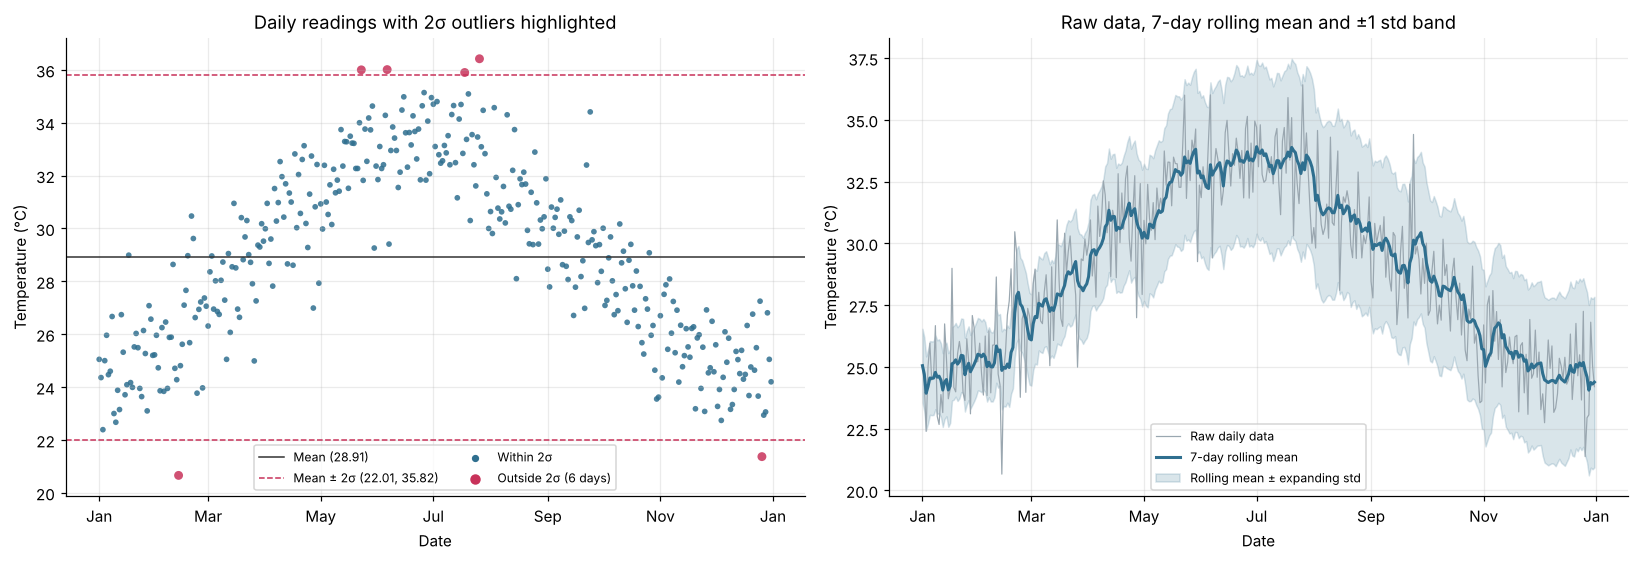

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.2))

colors = np.where(ts["outlier"], "#C8325A", "#2F6F8F")
ax1.scatter(ts.index, ts["value"], c=colors, s=np.where(ts["outlier"], 34, 14),
            alpha=0.85, edgecolors="none")
ax1.axhline(mu, color="#333", lw=1, label=f"Mean ({mu:.2f})")
ax1.axhline(hi, color="#C8325A", lw=1, ls="--", label=f"Mean ± 2σ ({lo:.2f}, {hi:.2f})")
ax1.axhline(lo, color="#C8325A", lw=1, ls="--")
ax1.scatter([], [], c="#2F6F8F", s=14, label="Within 2σ")
ax1.scatter([], [], c="#C8325A", s=34, label=f"Outside 2σ ({n_out} days)")
ax1.set_title("Daily readings with 2σ outliers highlighted")
ax1.set_xlabel("Date"); ax1.set_ylabel("Temperature (°C)")
ax1.legend(fontsize=8, loc="lower center", ncol=2)

ax2.plot(ts.index, ts["value"], color="#9AA7B0", lw=0.8, label="Raw daily data")
ax2.plot(ts.index, ts["roll_mean_7"], color="#2F6F8F", lw=2, label="7-day rolling mean")
ax2.fill_between(ts.index, ts["roll_mean_7"] - ts["exp_std_30"],
                 ts["roll_mean_7"] + ts["exp_std_30"], color="#2F6F8F", alpha=0.18,
                 label="Rolling mean ± expanding std")
ax2.set_title("Raw data, 7-day rolling mean and ±1 std band")
ax2.set_xlabel("Date"); ax2.set_ylabel("Temperature (°C)")
ax2.legend(fontsize=8, loc="lower center")

for ax in (ax1, ax2):
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("part2_subplots.png", dpi=150)
plt.show()

In [16]:
RESULTS["ts"] = {
    "dates": ts.index.strftime("%Y-%m-%d").tolist(),
    "value": ts["value"].round(2).tolist(),
    "roll": ts["roll_mean_7"].round(3).tolist(),
    "std": ts["exp_std_30"].round(3).tolist(),
    "outlier": ts["outlier"].tolist(),
    "nan_before": {k: int(v) for k, v in nan_before.items()},
    "nan_after": {k: int(nan_after[k]) for k in nan_before.index},
    "filled_rows": int(ts["is_filled"].sum()),
    "mu": round(mu, 3), "sigma": round(sigma, 3), "lo": round(lo, 3), "hi": round(hi, 3),
    "n_out": n_out,
}
with open("results.json", "w") as f:
    json.dump(RESULTS, f)
ts.to_csv("timeseries_2025.csv")
print("Saved results.json and timeseries_2025.csv")

Saved results.json and timeseries_2025.csv
